
# Task 4: Trend Prediction Analysis

## Project Overview

This project focuses on analyzing historical Netflix content trends and forecasting future content growth using time series analysis and machine learning techniques.

The objective is to understand how Netflix's content distribution has changed over the years, identify historical patterns, and build predictive models to estimate future trends.

## Objectives

- Prepare and analyze historical Netflix release-year data.
- Identify yearly content trends and growth patterns.
- Apply forecasting techniques to predict future content trends.
- Evaluate forecasting models using appropriate performance metrics.
- Visualize historical trends and future predictions.
- Interpret the results and identify meaningful insights.

## Dataset

The project uses the cleaned Netflix dataset prepared in Task 1: Netflix Data Cleaning.

The dataset contains information about Netflix movies and TV shows, including their release years and other relevant attributes.

## Technologies and Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

## Methodology

1. Dataset Loading and Inspection
2. Release-Year Data Preparation
3. Yearly Content Trend Analysis
4. Forecasting Model Development
5. Model Evaluation
6. Future Trend Prediction
7. Visualization and Interpretation

## Expected Outcome

A data-driven analysis of Netflix's historical content trends, along with forecasting models that estimate future content growth.


In [1]:


# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load cleaned Netflix dataset from Task 1

df = pd.read_csv(
    "D:/aiml and datascience/Auspify-Data-Science-Internship/Task-01-Data-Cleaning/data/processed/netflix_cleaned.csv"
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (8790, 15)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit,date_added_year,date_added_month,date_added_month_name
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min,2021,9,September
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season,2021,9,September
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season,2021,9,September
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min,2021,9,September
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min,2021,9,September


In [3]:
# Dataset overview

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   show_id                8790 non-null   object
 1   type                   8790 non-null   object
 2   title                  8790 non-null   object
 3   director               8790 non-null   object
 4   country                8790 non-null   object
 5   date_added             8790 non-null   object
 6   release_year           8790 non-null   int64 
 7   rating                 8790 non-null   object
 8   duration               8790 non-null   object
 9   listed_in              8790 non-null   object
 10  duration_value         8790 non-null   int64 
 11  duration_unit          8790 non-null   object
 12  date_added_year        8790 non-null   int64 
 13  date_added_month       8790 non-null   int64 
 14  date_added_month_name  8790 non-null   object
dtype

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit,date_added_year,date_added_month,date_added_month_name
count,8790,8790,8790,8790,8790,8790,8790.000000,8790,8790,8790,8790.000000,8790,8790.000000,8790.000000,8790
unique,8790,2,8786,4528,86,1713,NaN,14,220,513,NaN,2,NaN,NaN,12
top,s8786,Movie,Consequences,Not Available,United States,2020-01-01,NaN,TV-MA,1 Season,"Dramas, International Movies",NaN,min,NaN,NaN,July
freq,1,6126,2,2588,3240,110,NaN,3205,1791,362,NaN,6126,NaN,NaN,827
mean,NaN,NaN,NaN,NaN,NaN,NaN,2014.183163,NaN,NaN,NaN,69.934471,NaN,2018.873606,6.655859,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,8.825466,NaN,NaN,NaN,50.794433,NaN,1.573568,3.436103,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,1.000000,NaN,2008.000000,1.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,2.000000,NaN,2018.000000,4.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,88.500000,NaN,2019.000000,7.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,106.000000,NaN,2020.000000,10.000000,NaN


In [4]:
# Convert release_year into numeric format

df["release_year"] = pd.to_numeric(
    df["release_year"], errors="coerce"
)

# Remove missing release years
release_data = df.dropna(subset=["release_year"]).copy()

release_data["release_year"] = release_data["release_year"].astype(int)

# Count content released each year
yearly_content = (
    release_data.groupby("release_year")
    .size()
    .reset_index(name="Content_Count")
    .sort_values("release_year")
)

display(yearly_content.head(10))

,release_year,Content_Count
0,1925,1
1,1942,2
2,1943,3
3,1944,3
4,1945,4
5,1946,2
6,1947,1
7,1954,2
8,1955,3
9,1956,2


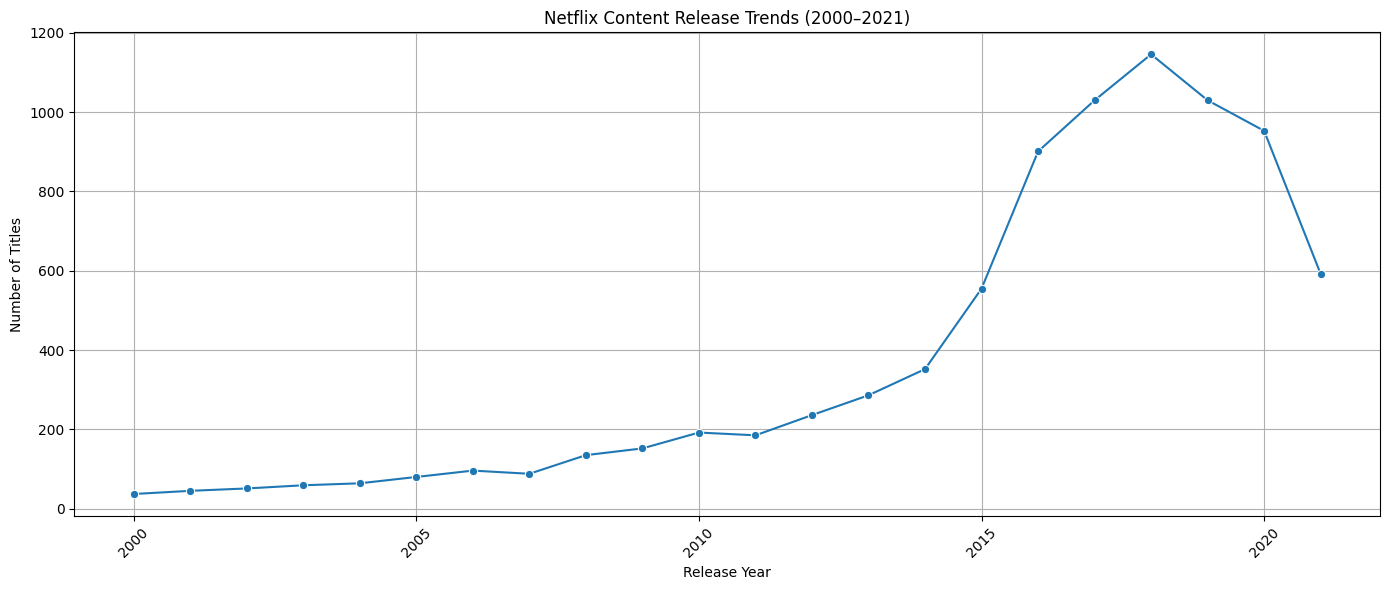

,release_year,Content_Count
64,2012,236
65,2013,286
66,2014,352
67,2015,555
68,2016,901
69,2017,1030
70,2018,1146
71,2019,1030
72,2020,953
73,2021,592


In [5]:

# Analyze Netflix content release trends

trend_data = yearly_content[
    yearly_content["release_year"] >= 2000
].copy()

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=trend_data,
    x="release_year",
    y="Content_Count",
    marker="o"
)

plt.title("Netflix Content Release Trends (2000–2021)")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

display(trend_data.tail(10))


In [6]:

# Prepare data for forecasting

forecast_data = trend_data.copy()

X = forecast_data[["release_year"]]
y = forecast_data["Content_Count"]

# Chronological 80-20 split
split_index = int(len(forecast_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Training period:",
      X_train["release_year"].min(), "-",
      X_train["release_year"].max())

print("Testing period:",
      X_test["release_year"].min(), "-",
      X_test["release_year"].max())


Training records: 17
Testing records: 5
Training period: 2000 - 2016
Testing period: 2017 - 2021


In [7]:

# Train Linear Regression model

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Generate predictions
lr_predictions = lr_model.predict(X_test)

# Evaluate model
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_mse = mean_squared_error(y_test, lr_predictions)
lr_rmse = np.sqrt(lr_mse)

print("Linear Regression Evaluation")
print("-----------------------------")
print("MAE:", round(lr_mae, 2))
print("MSE:", round(lr_mse, 2))
print("RMSE:", round(lr_rmse, 2))


Linear Regression Evaluation
-----------------------------
MAE: 380.66
MSE: 174719.57
RMSE: 417.99


In [8]:

# Previous year's actual value becomes the prediction

naive_predictions = y_test.shift(1)
naive_predictions.iloc[0] = y_train.iloc[-1]

naive_mae = mean_absolute_error(y_test, naive_predictions)
naive_mse = mean_squared_error(y_test, naive_predictions)
naive_rmse = np.sqrt(naive_mse)

print("Naive Forecast Evaluation")
print("-------------------------")
print("MAE:", round(naive_mae, 2))
print("MSE:", round(naive_mse, 2))
print("RMSE:", round(naive_rmse, 2))



Naive Forecast Evaluation
-------------------------
MAE: 159.8
MSE: 35960.6
RMSE: 189.63


In [9]:

model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Naive Forecast"],
    "MAE": [lr_mae, naive_mae],
    "MSE": [lr_mse, naive_mse],
    "RMSE": [lr_rmse, naive_rmse]
})

display(model_comparison.round(2))


,Model,MAE,MSE,RMSE
0,Linear Regression,380.66,174719.57,417.99
1,Naive Forecast,159.80,35960.60,189.63


In [10]:

# Train final model using complete historical data

final_model = LinearRegression()
final_model.fit(X, y)

# Generate future years
future_years = pd.DataFrame({
    "release_year": range(2022, 2027)
})

# Predict future content
future_predictions = final_model.predict(future_years)

future_results = pd.DataFrame({
    "Year": future_years["release_year"],
    "Linear_Regression_Prediction": np.maximum(
        0, np.round(future_predictions)
    ).astype(int),
    "Naive_Prediction": int(y.iloc[-1])
})

display(future_results)


,Year,Linear_Regression_Prediction,Naive_Prediction
0,2022,963,592
1,2023,1014,592
2,2024,1065,592
3,2025,1116,592
4,2026,1167,592


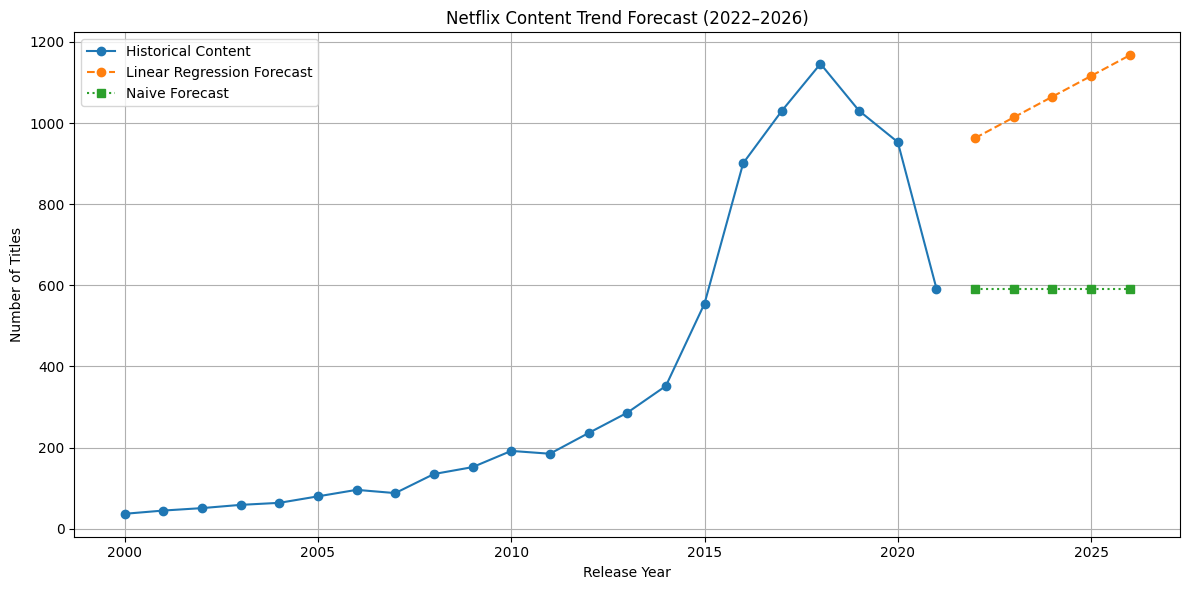

In [11]:

plt.figure(figsize=(12, 6))

plt.plot(
    forecast_data["release_year"],
    forecast_data["Content_Count"],
    marker="o",
    label="Historical Content"
)

plt.plot(
    future_results["Year"],
    future_results["Linear_Regression_Prediction"],
    marker="o",
    linestyle="--",
    label="Linear Regression Forecast"
)

plt.plot(
    future_results["Year"],
    future_results["Naive_Prediction"],
    marker="s",
    linestyle=":",
    label="Naive Forecast"
)

plt.title("Netflix Content Trend Forecast (2022–2026)")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [12]:

import os

# Output folder path
output_folder = r"D:\aiml and datascience\Auspify-Data-Science-Internship\Task-04-Trend-Prediction-Analysis\outputs"

# Create folder if it doesn't exist
os.makedirs(output_folder, exist_ok=True)

# Save CSV files
yearly_content.to_csv(
    os.path.join(output_folder, "yearly_content_trends.csv"),
    index=False
)

model_comparison.to_csv(
    os.path.join(output_folder, "model_comparison.csv"),
    index=False
)

future_results.to_csv(
    os.path.join(output_folder, "future_predictions.csv"),
    index=False
)

print("All output files saved successfully!")
print("Output location:", output_folder)


All output files saved successfully!
Output location: D:\aiml and datascience\Auspify-Data-Science-Internship\Task-04-Trend-Prediction-Analysis\outputs
